# Desarrollo de un modelo de clasificación para resistencia a la insulina (RI) utilizando machine learning: análisis basado en NHANES 2021–2023


**Contenido**
1. Configuración y librerías · 2. Configuración global · 3. Carga de datos · 4. Construcción de la cohorte · 5. Limpieza de variables y datos faltantes · 6. Definición del outcome · 7. Variables predictoras · 8. División train/test · 9. Imputación (MICE) · 10. Análisis descriptivo · 11. Preparación para machine learning · 12. Desbalance de clases · 13. Modelos · 14. Evaluación · 15. Interpretabilidad (SHAP, parsimonia, consenso, DeLong) · 16. Curvas de decisión clínica y calibración · 17. Resultados finales · 18. Correcciones y problemas pendientes

**OBJETIVO 1: Caracterizar el perfil clínico, bioquímico, dietético, antropométrico y sociodemográfico de los participantes de
NHANES 2021-2023, describiendo la distribución de la RI estimada por HOMA-IR**

## 1. Configuración y librerías

In [ ]:
%pip install -q "miceforest==6.0.5" pyampute xgboost shap "tabpfn>=6.0" "tabpfn-extensions[interpretability]" "requests>=2.32.5,<2.35"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 827.5/827.5 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.2/123.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 805.8/805.8 kB 27.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
# --- Python ---
import os
import time
import random
import warnings
from pathlib import Path
from importlib.metadata import version

# --- Manipulación de datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns

# --- Estadística ---
import scipy.stats as stats
from scipy.stats import spearmanr
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from pyampute.exploration.mcar_statistical_tests import MCARTest

# --- Machine Learning (scikit-learn) ---
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, accuracy_score, precision_score,
    f1_score, brier_score_loss, confusion_matrix, classification_report, ConfusionMatrixDisplay,
)

# --- Imputación ---
import miceforest as mf

# --- Modelos ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from tabpfn import TabPFNClassifier

# --- Interpretabilidad ---
import shap
from tabpfn_extensions.interpretability.shapiq import get_tabpfn_imputation_explainer
from tabpfn_extensions.interpretability import shapiq_to_shap_explanation

# --- Otras ---
import joblib

In [ ]:
for lib in ["pandas", "numpy", "scipy", "statsmodels", "scikit-learn", "miceforest",
            "xgboost", "shap", "tabpfn", "pyampute"]:
    print(f"{lib:<14} {version(lib)}")

pandas         2.2.3
numpy          2.1.3
scipy          1.16.3
statsmodels    0.15.0
scikit-learn   1.6.1
miceforest     6.0.5
xgboost        3.4.1
shap           0.52.0
tabpfn         9.0.0
pyampute       0.0.3


## 2. Configuración global


In [ ]:
# --- Reproducibilidad ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Rutas (Google Drive). Para mover el proyecto basta con cambiar BASE_DIR ---
BASE_DIR       = Path("/content/drive/MyDrive")
RUTA_VARIABLES = BASE_DIR / "TESIS MIDRI" / "nhanes_variables.csv"   # base consolidada NHANES
NHANES_DIR     = BASE_DIR / "NHANES"                                  # archivos .xpt originales
RUTA_DIQ       = NHANES_DIR / "DIQ_L.xpt"                             # cuestionario de diabetes
RESULTS_DIR    = BASE_DIR / "nhanes"                                  # datasets, tablas y modelos
FIG_DIR        = RESULTS_DIR / "figuras"                              # todos los gráficos

# --- Cohorte ---
EDAD_MINIMA              = 18
GLUCOSA_MAXIMA           = 126        # mg/dL; se conservan los participantes con glucosa <= 126
UMBRAL_FALTANTES_FILA    = 20         # % máximo de datos faltantes por participante
UMBRAL_FALTANTES_COLUMNA = 20         # % máximo de datos faltantes por variable

# Códigos NHANES de "se negó a responder / no sabe", SOLO en las variables de cuestionario que los usan.
# Verificar contra el codebook de cada módulo (DEMO_L, BPQ_L, DIQ_L, SMQ_L, ALQ_L, WHQ_L, PAQ_L).
CODIGOS_FALTANTES_POR_VARIABLE = {
    **{v: [7, 9] for v in ["NIVEL_EDUCATIVO", "DX_HIPERTENSION", "DX_HTA", "USO_ANTIHIPERTENSIVOS",
                           "DX_HIPERCOLESTEROLEMIA", "USO_HIPOLIPEMIANTES", "DX_PREDIABETES",
                           "MAS_100_CIGARRILLOS", "FRECUENCIA_CONSUMO", "ALCOHOL_VIDA", "INTENTO_PERDIDA_PESO"]},
    "ALCOHOL_12_MESES": [77, 99],      # ALQ121: escala 0–10, 7 y 9 son categorías válidas
    "NUMERO_BEBIDAS":   [777, 999],    # ALQ130: número de bebidas, 7 y 9 son valores válidos
    **{v: [7777, 9999] for v in ["FRECUENCIA_ACTIVIDAD_MODERADA", "DURACION_ACTIVIDAD_MODERADA",
                                 "FRECUENCIA_ACTIVIDAD_VIGOROSA", "DURACION_ACTIVIDAD_VIGOROSA",
                                 "TIEMPO_SENTADO"]},
}
# pandas.read_sas lee los ceros de los archivos .xpt como 5.397605e-79: se restauran a 0
UMBRAL_CERO_SAS = 1e-10

# --- Outcome ---
TARGET        = "RESISTENCIA_INSULINA"
HOMA_DIVISOR  = 405
HOMA_IR_CORTE = 2.5                   # RI = 1 si HOMA-IR > 2.5

# --- Partición, validación cruzada y búsqueda de hiperparámetros ---
TEST_SIZE       = 0.2
N_FOLDS         = 5
N_ITER_BUSQUEDA = 50
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# --- Imputación MICE (miceforest) ---
MICE_N_DATASETS    = 5
MICE_ITERACIONES   = 5
MICE_DATASET_USADO = 0

# --- Estadística descriptiva ---
ALFA = 0.05
N_BOOTSTRAP_NORMALIDAD = 2000

# --- Multicolinealidad ---
UMBRAL_VIF = 10
VARIABLES_PROTEGIDAS_VIF = ["IMC"]

# --- Interpretabilidad (SHAP sobre una submuestra del ENTRENAMIENTO; el test no se usa para seleccionar) ---
N_SHAP = 458                          # mismo tamaño que el test (costo computacional de TabPFN)
BUDGET_SHAP_TABPFN = 256
UMBRAL_IMPORTANCIA_ACUMULADA = 0.85
N_TOP_HEATMAP = 15

# --- Curvas de decisión clínica ---
UMBRALES_DCA = np.round(np.arange(0.01, 1.00, 0.01), 2)
UMBRALES_DCA_TABLA = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

ETIQUETAS_CLASES = ["Sin RI", "Con RI"]

# --- Opciones de visualización ---
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
warnings.filterwarnings("ignore", category=FutureWarning)


def guardar_figura(nombre, dpi=300):
    """Guarda la figura actual en FIG_DIR (Drive), para que no se pierda al cerrar Colab."""
    plt.savefig(FIG_DIR / nombre, dpi=dpi, bbox_inches="tight")

In [ ]:
try:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    if "TABPFN_TOKEN" not in os.environ:
        os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")
except ImportError:
    print("No se está ejecutando en Colab: verifique BASE_DIR y la variable de entorno TABPFN_TOKEN.")

FIG_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## 3. Carga de datos

El ciclo NHANES 2021- 2023 reclutó un total de 11.933 participantes entrevistados. De estos, 8.860 completaron
el componente de examen físico y 6.694 participaron en la encuesta dietética. Para los fines del presente estudio, el criterio
determinante de inclusión en la muestra analítica es la disponibilidad simultánea de mediciones válidas de insulina sérica
en ayuno (LBXIN) y glucosa plasmática en ayuno (LBXGLU), variables indispensables para el cálculo del índice HOMA-IR.
Este criterio restringe la muestra analítica a 3.483 participantes, lo que representa el 29,19% del total de participantes entrevistados en el ciclo.
La extracción y consolidación de los módulos de datos se realizó mediante visual code, descargando
los módulos DEMO_L, LAB_L, EXAM_L, DIQ_L, PAQ_L, DBQ_L y SMQ_L, con unión por identificador SEQN y verificación
de unicidad de registros.

In [ ]:
df = pd.read_csv(RUTA_VARIABLES)
diabetes = pd.read_sas(RUTA_DIQ, format="xport", encoding="utf-8")[["SEQN", "DIQ010", "DIQ050", "DIQ070"]]

print(f"nhanes_variables.csv: {df.shape[0]} participantes × {df.shape[1]} columnas")
print(f"DIQ_L.xpt:            {diabetes.shape[0]} participantes")
assert df["SEQN"].is_unique, "SEQN duplicado en la base consolidada"

nhanes_variables.csv: 11933 participantes × 55 columnas
DIQ_L.xpt:            11744 participantes


## 4. Construcción de la cohorte

Para la aplicación de los criterios de exclusión, se incorporó a la base de datos principal la información del cuestionario de diabetes de NHANES (DIQ_L), incluyendo las variables relacionadas con diagnóstico previo de diabetes, uso de insulina y consumo de medicamentos hipoglucemiantes. Posteriormente, se excluyeron los participantes menores de 18 años, aquellos con diagnóstico médico previo de diabetes mellitus, los que reportaron uso de insulina exógena y quienes utilizaban medicamentos hipoglucemiantes. Adicionalmente, se excluyeron los individuos con valores de glucosa en ayunas superiores a 126 mg/dL, con el fin de reducir la inclusión de casos compatibles con diabetes no diagnosticada. Tras aplicar estos criterios, las variables utilizadas únicamente para el proceso de selección fueron eliminadas de la base analítica final.

In [ ]:
flujo_cohorte = [{"Paso": "Participantes en nhanes_variables.csv", "Excluidos": 0, "n restante": len(df)}]


def aplicar_criterio(datos, conservar, descripcion):
    """Conserva las filas donde `conservar` es True y registra el número de excluidos."""
    n_antes = len(datos)
    datos = datos[conservar].copy()
    flujo_cohorte.append({"Paso": descripcion, "Excluidos": n_antes - len(datos), "n restante": len(datos)})
    return datos


# Inclusión: insulina y glucosa en ayuno disponibles (necesarias para HOMA-IR)
muestra = aplicar_criterio(df, df[["INSULINA", "GLUCOSA"]].notna().all(axis=1),
                           "Sin insulina o glucosa en ayuno")

# Exclusión: criterios clínicos (DIQ_L)
muestra = muestra.merge(diabetes, on="SEQN", how="left")
muestra = aplicar_criterio(muestra, muestra["EDAD"] >= EDAD_MINIMA, "Menores de 18 años")
muestra = aplicar_criterio(muestra, muestra["DIQ010"] != 1, "Diagnóstico previo de diabetes (DIQ010 = 1)")
muestra = aplicar_criterio(muestra, muestra["DIQ050"] != 1, "Uso de insulina (DIQ050 = 1)")
muestra = aplicar_criterio(muestra, muestra["DIQ070"] != 1, "Uso de hipoglucemiantes (DIQ070 = 1)")
muestra = aplicar_criterio(muestra, muestra["GLUCOSA"] <= GLUCOSA_MAXIMA, "Glucosa en ayuno > 126 mg/dL")
muestra = muestra.drop(columns=["DIQ010", "DIQ050", "DIQ070"])
pd.DataFrame(flujo_cohorte)

,Paso,Excluidos,n restante
0,Participantes en nhanes_variables.csv,0,11933
1,Sin insulina o glucosa en ayuno,8450,3483
2,Menores de 18 años,325,3158
3,Diagnóstico previo de diabetes (DIQ010 = 1),422,2736
4,Uso de insulina (DIQ050 = 1),0,2736
5,Uso de hipoglucemiantes (DIQ070 = 1),46,2690
6,Glucosa en ayuno > 126 mg/dL,111,2579


## 5. Limpieza de variables y datos faltantes
Primero se limpian los valores (5.1 códigos de no respuesta, 5.2 ceros del formato SAS). Después se aplican las exclusiones por datos faltantes (5.3 y 5.4), para que los porcentajes de faltantes sean los reales.

### 5.1 Códigos NHANES de "se negó / no sabe"

Los códigos de no respuesta de NHANES (7/9, 77/99, 777/999, 7777/9999 según la pregunta) se convirtieron en valores faltantes únicamente en las variables de cuestionario que los utilizan, de acuerdo con el codebook de cada módulo. En las variables de laboratorio, examen físico y dieta no se aplicó esta recodificación, porque en ellas los valores 7 y 9 corresponden a mediciones reales (por ejemplo, un BUN de 7 mg/dL).

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
conteo_codigos = {}
for col, codigos in CODIGOS_FALTANTES_POR_VARIABLE.items():
    if col in muestra.columns:
        es_codigo = muestra[col].isin(codigos)
        conteo_codigos[col] = int(es_codigo.sum())
        muestra[col] = muestra[col].mask(es_codigo)

print("Códigos de no respuesta convertidos en NaN:")
print(pd.Series(conteo_codigos)[lambda s: s > 0].to_string())

# Valores 7/9/7777/9999 que ahora se CONSERVAN (la versión original los convertía en NaN)
otras_numericas = [c for c in muestra.select_dtypes(include=[np.number]).columns
                   if c not in CODIGOS_FALTANTES_POR_VARIABLE and c not in ["SEQN", "ETNIA"]]
conservados = muestra[otras_numericas].isin([7, 9, 7777, 9999]).sum()
print("\nMediciones reales iguales a 7/9/7777/9999 que se conservan:")
print(conservados[conservados > 0].to_string())

Códigos de no respuesta convertidos en NaN:
DX_HIPERTENSION                   1
DX_HTA                            2
USO_ANTIHIPERTENSIVOS             2
DX_HIPERCOLESTEROLEMIA            7
USO_HIPOLIPEMIANTES               9
DX_PREDIABETES                    4
MAS_100_CIGARRILLOS               3
ALCOHOL_VIDA                      2
INTENTO_PERDIDA_PESO              2
ALCOHOL_12_MESES                  1
NUMERO_BEBIDAS                    7
FRECUENCIA_ACTIVIDAD_MODERADA     8
DURACION_ACTIVIDAD_MODERADA       6
FRECUENCIA_ACTIVIDAD_VIGOROSA     5
DURACION_ACTIVIDAD_VIGOROSA       3
TIEMPO_SENTADO                   12

Mediciones reales iguales a 7/9/7777/9999 que se conservan:
INSULINA           6
ALT              109
AST                8
HIERRO             1
INGESTA_FIBRA     16


### 5.2 Ceros del formato SAS

Al leer los archivos `.xpt` de NHANES con `pandas`, los valores iguales a cero se leen como `5.397605e-79`, un error conocido de la conversión del formato de punto flotante de SAS. Estos valores se restauraron a 0: corresponden, por ejemplo, a participantes que reportaron cero veces de actividad física (con las preguntas de duración omitidas por el patrón de salto del cuestionario) o cero minutos sentados. Tratarlos como faltantes habría hecho que MICE les imputara valores positivos.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
columnas_numericas = muestra.select_dtypes(include=[np.number]).columns
es_cero_sas = (muestra[columnas_numericas].abs() < UMBRAL_CERO_SAS) & (muestra[columnas_numericas] != 0)

print("Ceros SAS restaurados a 0, por variable:")
print(es_cero_sas.sum()[lambda s: s > 0].to_string())
muestra[columnas_numericas] = muestra[columnas_numericas].mask(es_cero_sas, 0.0)

# Ingestas de 0 kcal son fisiológicamente implausibles: se informan, no se modifican
n_cero_kcal = (muestra["INGESTA_CALORIAS"] == 0).sum()
if n_cero_kcal:
    print(f"\n⚠ {n_cero_kcal} participantes con INGESTA_CALORIAS = 0 (recordatorio posiblemente no válido).")

Ceros SAS restaurados a 0, por variable:
INGESTA_CALORIAS                    2
INGESTA_PROTEINA                    2
INGESTA_CARBOHIDRATOS               2
INGESTA_AZUCAR                      2
INGESTA_FIBRA                       3
INGESTA_GRASAS                      2
FRECUENCIA_ACTIVIDAD_MODERADA     421
FRECUENCIA_ACTIVIDAD_VIGOROSA    1284
TIEMPO_SENTADO                      2
ALCOHOL_12_MESES                  290

⚠ 2 participantes con INGESTA_CALORIAS = 0 (recordatorio posiblemente no válido).


### 5.3 Exclusión de participantes con más del 20 % de datos faltantes

Se eliminaron los participantes cuyos datos faltantes superaban el 20% del total

In [ ]:
pct_faltantes_fila = muestra.isnull().mean(axis=1) * 100
muestra = aplicar_criterio(muestra, pct_faltantes_fila <= UMBRAL_FALTANTES_FILA,
                           f"> {UMBRAL_FALTANTES_FILA}% de datos faltantes")

flujo_cohorte = pd.DataFrame(flujo_cohorte)
flujo_cohorte

,Paso,Excluidos,n restante
0,Participantes en nhanes_variables.csv,0,11933
1,Sin insulina o glucosa en ayuno,8450,3483
2,Menores de 18 años,325,3158
3,Diagnóstico previo de diabetes (DIQ010 = 1),422,2736
4,Uso de insulina (DIQ050 = 1),0,2736
5,Uso de hipoglucemiantes (DIQ070 = 1),46,2690
6,Glucosa en ayuno > 126 mg/dL,111,2579
7,> 20% de datos faltantes,294,2285


### Diagrama de flujo STROBE


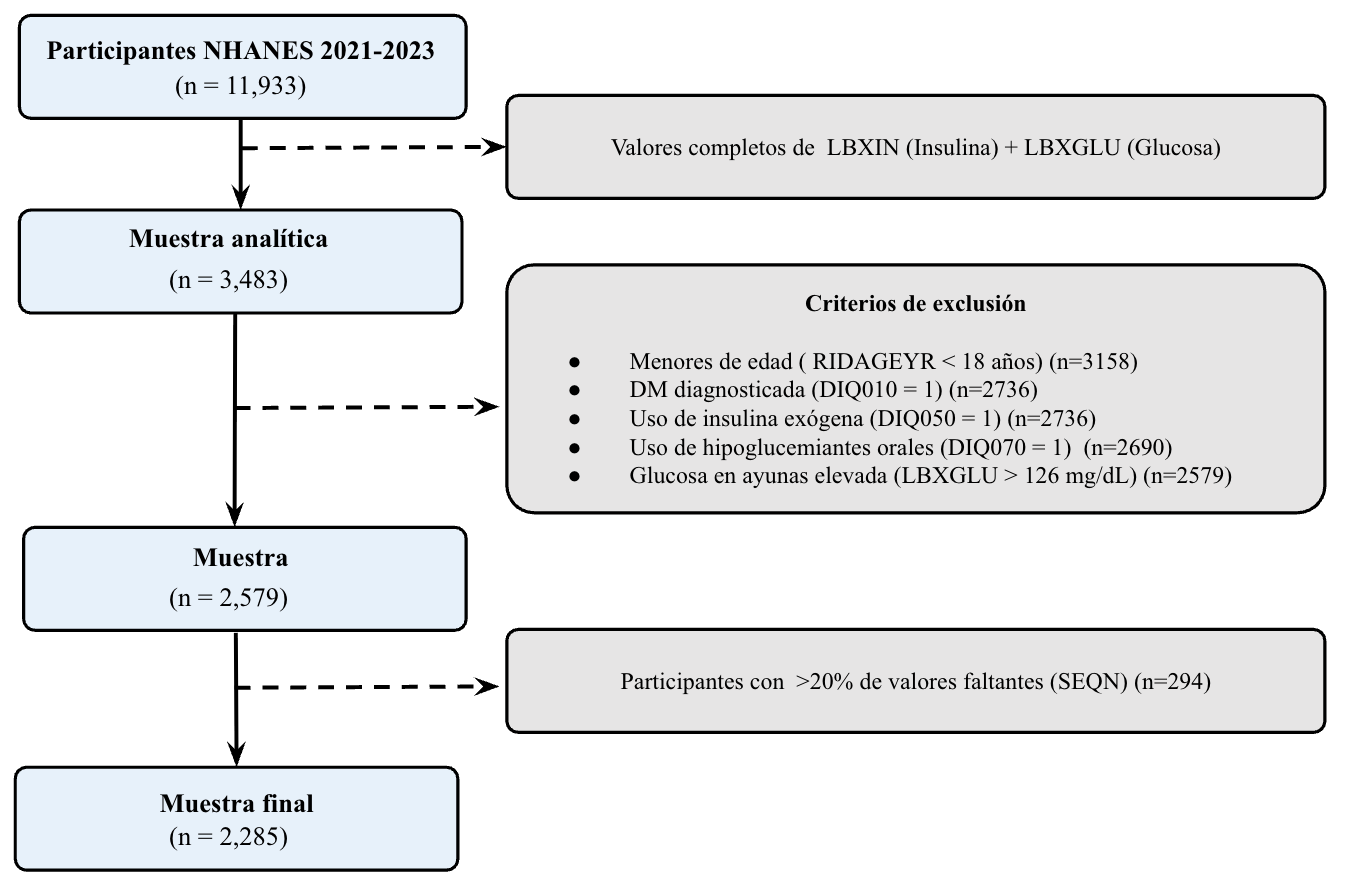

### 5.4 Exclusión de variables con más del 20 % de datos faltantes

Se evaluó el porcentaje de datos faltantes de cada variable después de la limpieza de códigos de no respuesta y de ceros del formato SAS, y se excluyeron las variables con más del 20 % de valores faltantes. Se excluyó además la frecuencia de actividad física vigorosa, porque su duración y su unidad temporal quedaron fuera por este criterio.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
resumen_faltantes = pd.DataFrame({
    "n_faltantes": muestra.isna().sum(),
    "porcentaje_faltantes": (muestra.isna().mean() * 100).round(2),
}).sort_values("porcentaje_faltantes", ascending=False)
print(f"Variables con al menos un faltante: {(resumen_faltantes['n_faltantes'] > 0).sum()} de {muestra.shape[1]}")
display(resumen_faltantes[resumen_faltantes["n_faltantes"] > 0])

Variables con al menos un faltante: 44 de 55


,n_faltantes,porcentaje_faltantes
FERRITINA,1712,74.92
USO_ANTIHIPERTENSIVOS,1571,68.75
DX_HTA,1570,68.71
FRECUENCIA_CONSUMO,1449,63.41
DURACION_ACTIVIDAD_VIGOROSA,1080,47.26
UNIDAD_ACTIVIDAD_VIGOROSA,1078,47.18
NUMERO_BEBIDAS,632,27.66
ALCOHOL_12_MESES,353,15.45
DURACION_ACTIVIDAD_MODERADA,325,14.22
UNIDAD_ACTIVIDAD_MODERADA,320,14.00


In [ ]:
faltantes_por_columna = muestra.isnull().mean() * 100
columnas_excluidas_faltantes = faltantes_por_columna[faltantes_por_columna > UMBRAL_FALTANTES_COLUMNA].index.tolist()
columnas_excluidas = list(dict.fromkeys(columnas_excluidas_faltantes + ["FRECUENCIA_ACTIVIDAD_VIGOROSA"]))

dataset_final = muestra.drop(columns=columnas_excluidas)
print(f"Variables excluidas por > {UMBRAL_FALTANTES_COLUMNA}% de faltantes ({len(columnas_excluidas_faltantes)}): "
      f"{columnas_excluidas_faltantes}")
print(f"dataset_final: {dataset_final.shape[0]} filas × {dataset_final.shape[1]} columnas")

Variables excluidas por > 20% de faltantes (7): ['FERRITINA', 'DX_HTA', 'USO_ANTIHIPERTENSIVOS', 'UNIDAD_ACTIVIDAD_VIGOROSA', 'DURACION_ACTIVIDAD_VIGOROSA', 'FRECUENCIA_CONSUMO', 'NUMERO_BEBIDAS']
dataset_final: 2285 filas × 47 columnas


### 5.5 Actividad física moderada en minutos por semana

La actividad física moderada se expresó en minutos por semana (ACTIVIDAD_MODERADA_MIN_SEMANA) a partir de tres preguntas: número de veces (FRECUENCIA_ACTIVIDAD_MODERADA), unidad temporal de esa frecuencia (día, semana, mes o año; UNIDAD_ACTIVIDAD_MODERADA) y minutos por sesión (DURACION_ACTIVIDAD_MODERADA). Minutos/semana = veces × minutos por vez × factor de la unidad (día = 7; semana = 1; mes = 1/4,345; año = 1/52). A los participantes que reportaron cero veces se les asignó 0 minutos por semana.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
frecuencia = dataset_final["FRECUENCIA_ACTIVIDAD_MODERADA"]
duracion = dataset_final["DURACION_ACTIVIDAD_MODERADA"]
unidad = dataset_final["UNIDAD_ACTIVIDAD_MODERADA"]
print(unidad.value_counts(dropna=False).to_string(), "\n")

FACTOR_A_SEMANA = {"D": 7, "W": 1, "M": 1 / 4.345, "Y": 1 / 52}
dataset_final["ACTIVIDAD_MODERADA_MIN_SEMANA"] = np.where(
    frecuencia == 0, 0.0, frecuencia * duracion * unidad.map(FACTOR_A_SEMANA)
)
dataset_final = dataset_final.drop(columns=["FRECUENCIA_ACTIVIDAD_MODERADA", "UNIDAD_ACTIVIDAD_MODERADA",
                                            "DURACION_ACTIVIDAD_MODERADA"])

print(f"Participantes con 0 min/semana: {(dataset_final['ACTIVIDAD_MODERADA_MIN_SEMANA'] == 0).sum()}")
print(dataset_final["ACTIVIDAD_MODERADA_MIN_SEMANA"].describe().round(2).to_string())

dataset_final.to_csv(NHANES_DIR / "dataset_final.csv", index=False)

UNIDAD_ACTIVIDAD_MODERADA
W      1568
NaN     320
D       254
M       119
Y        24 

Participantes con 0 min/semana: 312
count    2272.00
mean      234.56
std       388.42
min         0.00
25%        45.00
50%       120.00
75%       280.00
max      6300.00


### 5.6 Test de Little (MCAR)

In [ ]:
variables_varianza_cero = dataset_final.columns[dataset_final.nunique(dropna=True) <= 1].tolist()
df_para_mcar = dataset_final.drop(columns=variables_varianza_cero + ["SEQN"])

p_mcar = MCARTest(method="little")(df_para_mcar)
print(f"Variables en el test: {df_para_mcar.shape[1]} (excluidas: {variables_varianza_cero + ['SEQN']})")
print(f"Test de Little: p = {p_mcar:.4g} → "
      + ("se rechaza MCAR" if p_mcar < ALFA else "no se rechaza MCAR"))

Variables en el test: 44 (excluidas: ['SEQN'])
Test de Little: p = 0 → se rechaza MCAR


El test de Little arrojó un valor p significativo, por lo que se rechaza la hipótesis de que los datos faltantes sean completamente aleatorios (MCAR). Este resultado debe interpretarse con cautela: con el tamaño muestral del estudio, el test tiene alta potencia para detectar desviaciones pequeñas, y rechazar MCAR no demuestra que los datos sean MAR. El resultado es compatible con el uso de imputación múltiple por ecuaciones encadenadas (MICE) bajo el supuesto de datos faltantes al azar (MAR).

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

## 6. Definición del outcome: resistencia a la insulina (HOMA-IR > 2.5)

A partir de las concentraciones de glucosa (mg/dL) e insulina (µU/mL) en ayuno se calculó el índice HOMA-IR (Homeostatic Model Assessment for Insulin Resistance) mediante la fórmula estándar HOMA-IR = (Glucosa × Insulina) / 405. A partir de esta variable continua se construyó la variable objetivo binaria, categorizando como positivos (resistencia a la insulina = 1) a los participantes con HOMA-IR > 2.5, punto de corte ampliamente utilizado en la literatura biomédica. La distribución de clases resultante se muestra en la salida siguiente; el desbalance leve-moderado se abordó mediante ponderación de clases (class weighting) en la fase de modelado.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
dataset_final["HOMA_IR"] = (dataset_final["GLUCOSA"] * dataset_final["INSULINA"]) / HOMA_DIVISOR
assert dataset_final["HOMA_IR"].notna().all(), "Hay participantes sin HOMA-IR: el outcome quedaría mal definido"
dataset_final[TARGET] = (dataset_final["HOMA_IR"] > HOMA_IR_CORTE).astype(int)

print(dataset_final[["GLUCOSA", "INSULINA", "HOMA_IR"]].describe().round(2).T.to_string(), "\n")
distribucion = dataset_final[TARGET].value_counts().sort_index()
print(pd.DataFrame({"n": distribucion, "%": (distribucion / len(dataset_final) * 100).round(1)}).to_string())

           count   mean    std    min    25%    50%     75%     max
GLUCOSA   2285.0  99.42   9.60  59.00  93.00  99.00  105.00  126.00
INSULINA  2285.0  11.40  10.63   0.35   5.49   8.70   13.89  188.42
HOMA_IR   2285.0   2.87   2.85   0.07   1.30   2.09    3.52   49.31 

                         n     %
RESISTENCIA_INSULINA            
0                     1333  58.3
1                      952  41.7


## 7. Variables predictoras
Lista única de variables por dominio. De aquí salen las listas usadas en la Tabla 1, el VIF y los modelos.

In [ ]:
# dominio: ([categóricas], [cuantitativas])
VARIABLES_POR_DOMINIO = {
    "Demográficas":             (["GENERO", "ETNIA", "NIVEL_EDUCATIVO"], ["EDAD"]),
    "Antropométricas":          ([], ["PESO", "ALTURA", "IMC", "CINTURA", "BRAZO", "CADERA"]),
    "Clínicas":                 (["DX_HIPERTENSION", "DX_HIPERCOLESTEROLEMIA", "USO_HIPOLIPEMIANTES", "DX_PREDIABETES"],
                                 ["PAD", "PAS", "PULSO"]),
    "Componentes del desenlace": ([], ["GLUCOSA", "INSULINA", "HOMA_IR"]),
    "Bioquímicas":              ([], ["COLESTEROL_HDL", "TRIGLICERIDOS", "COLESTEROL_LDL", "COLESTEROL_TOTAL",
                                      "PROTEINA_C_REACTIVA", "ALT", "AST", "BUN", "CREATININA", "CPK",
                                      "HIERRO", "MAGNESIO", "VITAMINA_D"]),
    "Nutricionales":            ([], ["INGESTA_CALORIAS", "INGESTA_PROTEINA", "INGESTA_CARBOHIDRATOS",
                                      "INGESTA_AZUCAR", "INGESTA_FIBRA", "INGESTA_GRASAS"]),
    "Estilo de vida":           (["MAS_100_CIGARRILLOS", "ALCOHOL_VIDA", "INTENTO_PERDIDA_PESO"],
                                 ["TIEMPO_SENTADO", "ACTIVIDAD_MODERADA_MIN_SEMANA"]),
}
VARS_CATEGORICAS   = [v for categoricas, _ in VARIABLES_POR_DOMINIO.values() for v in categoricas]
VARS_CUANTITATIVAS = [v for _, cuantitativas in VARIABLES_POR_DOMINIO.values() for v in cuantitativas]

# GLUCOSA, INSULINA y HOMA_IR definen el outcome: solo se describen, nunca se usan como predictores
COLUMNAS_DESENLACE = ["GLUCOSA", "INSULINA", "HOMA_IR"]
VARS_CUANTITATIVAS_PREDICTORAS = [v for v in VARS_CUANTITATIVAS if v not in COLUMNAS_DESENLACE]

ETIQUETAS = {
    "GENERO": {1: "Hombre", 2: "Mujer"},
    "ETNIA": {1: "Mexicano-Americano", 2: "Otro Hispano", 3: "Blanco no Hispano",
              4: "Negro no Hispano", 6: "Asiatico no Hispano", 7: "Otra raza / Multirracial"},
    "NIVEL_EDUCATIVO": {1: "Menos de 9° grado", 2: "9°-11° grado (incompleto)", 3: "Bachillerato / GED",
                        4: "Universidad incompleta / AA", 5: "Universidad completa o superior"},
    **{v: {1: "Si", 2: "No"} for v in ["DX_HIPERTENSION", "DX_HIPERCOLESTEROLEMIA", "USO_HIPOLIPEMIANTES",
                                       "DX_PREDIABETES", "MAS_100_CIGARRILLOS", "ALCOHOL_VIDA",
                                       "INTENTO_PERDIDA_PESO"]},
}

# Todas las variables del estudio deben estar presentes
faltan = set(VARS_CATEGORICAS + VARS_CUANTITATIVAS) - set(dataset_final.columns)
assert not faltan, f"Variables del estudio excluidas por faltantes: {faltan}"

# Variables que ahora superan el filtro de faltantes pero no forman parte del conjunto aprobado en la tesis:
# se excluyen para no cambiar las variables seleccionadas (decisión a consultar, ver sección 18)
no_previstas = sorted(set(dataset_final.columns) - set(VARS_CATEGORICAS + VARS_CUANTITATIVAS) - {"SEQN", TARGET})
if no_previstas:
    print(f"⚠ Variables no previstas que superan el filtro de faltantes (se excluyen): {no_previstas}")
    dataset_final = dataset_final.drop(columns=no_previstas)

pd.DataFrame([(dominio, "Categórica", v) for dominio, (cat, _) in VARIABLES_POR_DOMINIO.items() for v in cat] +
             [(dominio, "Cuantitativa", v) for dominio, (_, cuant) in VARIABLES_POR_DOMINIO.items() for v in cuant],
             columns=["Dominio", "Tipo", "Variable"]).sort_values(["Dominio", "Tipo"], kind="stable")

⚠ Variables no previstas que superan el filtro de faltantes (se excluyen): ['ALCOHOL_12_MESES']


,Dominio,Tipo,Variable
11,Antropométricas,Cuantitativa,PESO
12,Antropométricas,Cuantitativa,ALTURA
13,Antropométricas,Cuantitativa,IMC
14,Antropométricas,Cuantitativa,CINTURA
15,Antropométricas,Cuantitativa,BRAZO
16,Antropométricas,Cuantitativa,CADERA
23,Bioquímicas,Cuantitativa,COLESTEROL_HDL
24,Bioquímicas,Cuantitativa,TRIGLICERIDOS
25,Bioquímicas,Cuantitativa,COLESTEROL_LDL
26,Bioquímicas,Cuantitativa,COLESTEROL_TOTAL


## 8. División train / test

Posteriormente, la muestra se dividió en conjuntos de entrenamiento (80%) y prueba (20%) mediante muestreo aleatorio estratificado según la variable objetivo, con el fin de preservar la proporción de clases en ambos subconjuntos y garantizar una evaluación representativa del desempeño del modelo. Esta partición se realizó previamente a cualquier procedimiento de imputación de datos faltantes, con el objetivo de evitar fuga de información (data leakage) entre los conjuntos de entrenamiento y prueba.

In [ ]:
train_df, test_df = train_test_split(
    dataset_final, test_size=TEST_SIZE, stratify=dataset_final[TARGET], random_state=SEED
)

print(f"Train: {len(train_df)} ({len(train_df)/len(dataset_final):.1%})  |  Test: {len(test_df)} ({len(test_df)/len(dataset_final):.1%})")
pd.DataFrame({"Train": train_df[TARGET].value_counts(normalize=True).round(3),
              "Test": test_df[TARGET].value_counts(normalize=True).round(3)})

Train: 1828 (80.0%)  |  Test: 457 (20.0%)


,Train,Test
RESISTENCIA_INSULINA,,
0,0.583,0.584
1,0.417,0.416


## 9. Imputación de datos faltantes (MICE – miceforest)

Los datos faltantes de las variables predictoras se imputaron con imputación por ecuaciones encadenadas (MICE), implementada con la librería `miceforest`. El kernel de imputación se ajustó exclusivamente con el conjunto de entrenamiento y después se aplicó al conjunto de prueba mediante `impute_new_data()`, sin reajustarlo. La variable objetivo y sus componentes (glucosa, insulina y HOMA-IR) se excluyeron del modelo de imputación: si se usaran, los predictores del conjunto de prueba se completarían con información del desenlace, que no está disponible al aplicar el modelo a un paciente nuevo (*data leakage*). El kernel generó 5 conjuntos imputados con 5 iteraciones cada uno; los análisis se realizaron sobre el primer conjunto imputado (imputación única estocástica).

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
COLUMNAS_FUERA_DE_IMPUTACION = ["SEQN", TARGET] + COLUMNAS_DESENLACE
assert train_df[COLUMNAS_DESENLACE + [TARGET]].notna().all().all()

train_predictores = train_df.drop(columns=COLUMNAS_FUERA_DE_IMPUTACION).reset_index(drop=True)
test_predictores = test_df.drop(columns=COLUMNAS_FUERA_DE_IMPUTACION).reset_index(drop=True)

# Kernel ajustado SOLO con los predictores del entrenamiento (sin outcome)
kernel = mf.ImputationKernel(train_predictores, num_datasets=MICE_N_DATASETS, random_state=SEED)
kernel.mice(iterations=MICE_ITERACIONES)
test_kernel = kernel.impute_new_data(new_data=test_predictores, random_state=SEED)


def reincorporar_desenlace(imputado, original):
    """Agrega de nuevo el outcome y sus componentes (no imputados) en el orden original de columnas."""
    completo = imputado.copy()
    for col in COLUMNAS_DESENLACE + [TARGET]:
        completo[col] = original[col].to_numpy()
    return completo[[c for c in original.columns if c != "SEQN"]]


train_imputado = reincorporar_desenlace(kernel.complete_data(dataset=MICE_DATASET_USADO), train_df)
test_imputado = reincorporar_desenlace(test_kernel.complete_data(dataset=MICE_DATASET_USADO), test_df)
print(f"Train imputado: {train_imputado.shape} | NaN restantes: {train_imputado.isna().sum().sum()}")
print(f"Test imputado:  {test_imputado.shape} | NaN restantes: {test_imputado.isna().sum().sum()}")

Train imputado: (1828, 45) | NaN restantes: 0
Test imputado:  (457, 45) | NaN restantes: 5


In [ ]:
# NaN residuales en el test tras impute_new_data: se completan con la mediana (continuas)
# o la moda (binarias) del conjunto de ENTRENAMIENTO imputado
for col in test_imputado.columns[test_imputado.isna().any()]:
    n_afectados = test_imputado[col].isna().sum()
    if pd.api.types.is_numeric_dtype(train_imputado[col]) and train_imputado[col].nunique() > 2:
        valor_relleno, metodo = train_imputado[col].median(), "mediana"
    else:
        valor_relleno, metodo = train_imputado[col].mode()[0], "moda"
    test_imputado[col] = test_imputado[col].fillna(valor_relleno)
    print(f"{col}: {n_afectados} valor(es) rellenado(s) con {valor_relleno} ({metodo} de train)")

assert test_imputado.isna().sum().sum() == 0

train_imputado.to_csv(RESULTS_DIR / "train_imputado.csv", index=False)
test_imputado.to_csv(RESULTS_DIR / "test_imputado.csv", index=False)

## 10. Análisis descriptivo

Se construyó la Tabla 1 del estudio con la muestra analítica completa (entrenamiento + prueba combinados), estratificada según la variable objetivo (resistencia a la insulina).

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

Las variable se clasificaron en dos grupos según su naturaleza:  categóricas y cuantitativas. Las variables categóricas fueron recodificadas de sus valores numéricos originales a etiquetas descriptivas para facilitar la interpretación de la tabla. Cabe señalar que las variables GLUCOSA, INSULINA y HOMA_IR se incluyeron en la Tabla 1 con fines  descriptivos y de verificación de la construcción del desenlace, dado que constituyen sus componentes de cálculo directo y fueron excluidas del conjunto de variables predictoras utilizadas en la fase de modelado, a fin de evitar data leakage entre el desenlace y los predictores del modelo de clasificación

In [ ]:
muestra_analitica = pd.concat([train_imputado, test_imputado], axis=0, ignore_index=True)
print(f"Muestra analítica: {muestra_analitica.shape[0]} participantes")
print(muestra_analitica[TARGET].value_counts().sort_index().to_string())

### 10.1 Funciones estadísticas

Para las variables categóricas, la asociación con el desenlace se evaluó mediante la prueba de Chi-cuadrado de independencia. En el caso de tablas de contingencia 2×2, se aplicó adicionalmente el criterio de frecuencias esperadas mínimas: cuando alguna celda presentó un valor esperado inferior a 5, se utilizó la prueba exacta de Fisher

Para las variables categóricas, el resumen descriptivo se calculó dentro de cada grupo de comparación (con y sin resistencia a la insulina), expresando cada categoría como frecuencia absoluta y porcentaje relativo al total de su respectivo grupo (n, %)

La evaluación de normalidad mediante la prueba de Kolmogorov-Smirnov con corrección de Lilliefors mostró rechazo de la hipótesis nula en la mayoría de las variables cuantitativas. Este resultado debe interpretarse con cautela, dado que la potencia estadística de las pruebas de normalidad aumenta considerablemente con el tamaño muestral, de modo que incluso desviaciones mínimas y de escasa relevancia práctica respecto a la distribución normal son detectadas como estadísticamente significativas cuando n es grande (Ghasemi & Zahediasl, 2012). Con tamaños muestrales de aproximadamente 1.830 (entrenamiento) y 458 (prueba) observaciones, era esperable que la prueba de Lilliefors resultara altamente sensible a asimetrías leves, lo cual explica que la mayoría de las variables cuantitativas fueran evaluadas mediante la prueba no paramétrica de Mann-Whitney U. Cabe señalar que, de acuerdo con el teorema del límite central, los estadísticos de prueba paramétricos (t de Student, t de Welch) tienden a ser robustos ante desviaciones moderadas de normalidad cuando el tamaño muestral es suficientemente grande (Lumley et al., 2002), por lo que la decisión de aplicar pruebas no paramétricas en este estudio se adoptó como criterio conservador y sistemático, priorizando la consistencia metodológica sobre la elección caso por caso basada en inspección visual.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
def normalidad_lilliefors(serie, n_bootstrap=N_BOOTSTRAP_NORMALIDAD, seed=SEED):
    """Estadístico D y valor p de Lilliefors. Con n_bootstrap > 0 agrega el IC 95 % bootstrap de D."""
    datos = serie.dropna().values
    d_stat, p_valor = lilliefors(datos, dist="norm")
    resultado = {"D": d_stat, "p_valor": p_valor, "es_normal": p_valor > ALFA}
    if n_bootstrap:
        rng = np.random.default_rng(seed)
        boot = [lilliefors(rng.choice(datos, size=len(datos), replace=True), dist="norm")[0]
                for _ in range(n_bootstrap)]
        resultado["IC_95_inf"], resultado["IC_95_sup"] = np.percentile(boot, [2.5, 97.5])
    return resultado


def comparar_categorica(tabla):
    """Chi-cuadrado; en tablas 2×2 con alguna frecuencia esperada < 5 se usa la prueba exacta de Fisher."""
    _, p_chi2, _, esperadas = stats.chi2_contingency(tabla)
    if tabla.shape == (2, 2) and (esperadas < 5).any():
        return stats.fisher_exact(tabla)[1], "Fisher exacto"
    return p_chi2, "Chi-cuadrado"


def comparar_cuantitativa(grupo_a, grupo_b):
    """t de Student / Welch (según Levene) si ambos grupos son normales por Lilliefors; si no, Mann-Whitney U."""
    grupo_a, grupo_b = grupo_a.dropna(), grupo_b.dropna()
    es_normal = (normalidad_lilliefors(grupo_a, n_bootstrap=0)["es_normal"]
                 and normalidad_lilliefors(grupo_b, n_bootstrap=0)["es_normal"])
    if es_normal:
        varianzas_iguales = stats.levene(grupo_a, grupo_b)[1] > ALFA
        p = stats.ttest_ind(grupo_a, grupo_b, equal_var=varianzas_iguales)[1]
        return p, ("t-Student" if varianzas_iguales else "t-Welch"), True
    return stats.mannwhitneyu(grupo_a, grupo_b, alternative="two-sided")[1], "Mann-Whitney", False


def resumir_cuantitativa(serie, es_normal):
    """Media ± DE si la distribución es normal; mediana [RIC] en caso contrario."""
    serie = serie.dropna()
    if es_normal:
        return f"{serie.mean():.2f} ± {serie.std():.2f}"
    q1, mediana, q3 = serie.quantile([0.25, 0.5, 0.75])
    return f"{mediana:.2f} [{q1:.2f}–{q3:.2f}]"


def resumir_categoria(serie, codigo):
    """n (%) de la categoría `codigo` respecto al total del grupo."""
    n, total = (serie == codigo).sum(), len(serie)
    return f"{n} ({n / total * 100:.1f}%)" if total else "0 (0.0%)"


def grupos_por_desenlace(df, var):
    return df.loc[df[TARGET] == 0, var], df.loc[df[TARGET] == 1, var]

### 10.2 Evaluación visual de la normalidad (conjunto de entrenamiento)

In [ ]:
def graficar_normalidad(df, var):
    grupo0, grupo1 = (g.dropna() for g in grupos_por_desenlace(df, var))
    r0, r1 = normalidad_lilliefors(grupo0, n_bootstrap=0), normalidad_lilliefors(grupo1, n_bootstrap=0)

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    fig.suptitle(f"Evaluación visual de normalidad: {var}", fontsize=13)
    axes[0, 0].hist(grupo0, bins=30, color="steelblue", edgecolor="white")
    axes[0, 0].set_title("Sin RI - Histograma")
    axes[0, 1].hist(grupo1, bins=30, color="indianred", edgecolor="white")
    axes[0, 1].set_title("Con RI - Histograma")
    for ax, grupo, r, nombre in [(axes[1, 0], grupo0, r0, "Sin RI"), (axes[1, 1], grupo1, r1, "Con RI")]:
        stats.probplot(grupo, dist="norm", plot=ax)
        p_str = "<.001" if r["p_valor"] < 0.001 else f"{r['p_valor']:.4f}"
        ax.set_title(f"{nombre} - QQ-plot\nD={r['D']:.3f}, p={p_str}")
    plt.tight_layout()
    guardar_figura(f"qq_{var}.png", dpi=200)
    plt.show()
    plt.close()


for var in VARS_CUANTITATIVAS:
    graficar_normalidad(train_imputado, var)

In [ ]:
# Tabla de normalidad (Lilliefors con IC 95 % bootstrap del estadístico D)
filas_normalidad = []
for var in VARS_CUANTITATIVAS:
    for conjunto, df_ref in [("Overall", muestra_analitica), ("Train", train_imputado), ("Test", test_imputado)]:
        for grupo, serie in zip(["Sin_RI", "Con_RI"], grupos_por_desenlace(df_ref, var)):
            if serie.dropna().shape[0] < 4:
                continue
            r = normalidad_lilliefors(serie)
            filas_normalidad.append({
                "Variable": var, "Conjunto": conjunto, "Grupo": grupo, "n": serie.dropna().shape[0],
                "D": round(r["D"], 4), "IC_95_inf": round(r["IC_95_inf"], 4), "IC_95_sup": round(r["IC_95_sup"], 4),
                "p_valor": "<.001" if r["p_valor"] < 0.001 else round(r["p_valor"], 4),
                "Normal": "Sí" if r["es_normal"] else "No",
            })

tabla_normalidad = pd.DataFrame(filas_normalidad)
tabla_normalidad.to_csv(RESULTS_DIR / "normalidad_lilliefors.csv", index=False)
tabla_normalidad

### 10.3 Tabla 1

La Tabla 1 se construyó integrando los resultados de las funciones descritas previamente, generando una fila por cada variable cuantitativa y una fila por cada categoría de las variables categóricas. Para cada variable se calculó el resumen descriptivo (media ± desviación estándar, mediana [rango intercuartílico], o frecuencia y porcentaje, según corresponda) en tres subconjuntos: la muestra completa, el conjunto de entrenamiento y el conjunto de prueba, discriminando en cada uno los participantes con y sin resistencia a la insulina. Los valores de p se calcularon de forma independiente dentro del conjunto de entrenamiento y dentro del conjunto de prueba, evaluando en ambos casos la asociación entre la variable correspondiente y el desenlace.

In [ ]:
def construir_tabla_1(df, prefijo):
    """Resumen por grupo (Sin RI / Con RI) y valor p de la asociación con el desenlace."""
    filas = []
    for var in VARS_CATEGORICAS:
        p, prueba = comparar_categorica(pd.crosstab(df[var], df[TARGET]))
        g0, g1 = grupos_por_desenlace(df, var)
        for i, (codigo, etiqueta) in enumerate(ETIQUETAS[var].items()):
            filas.append({"Variable": var if i == 0 else "", "Categoria": etiqueta,
                          f"{prefijo}_Sin_RI": resumir_categoria(g0, codigo),
                          f"{prefijo}_Con_RI": resumir_categoria(g1, codigo),
                          f"p_{prefijo.lower()}": round(p, 4) if i == 0 else "",
                          f"Test_usado_{prefijo.lower()}": prueba if i == 0 else ""})
    for var in VARS_CUANTITATIVAS:
        g0, g1 = grupos_por_desenlace(df, var)
        p, prueba, es_normal = comparar_cuantitativa(g0, g1)
        filas.append({"Variable": var, "Categoria": "-",
                      f"{prefijo}_Sin_RI": resumir_cuantitativa(g0, es_normal),
                      f"{prefijo}_Con_RI": resumir_cuantitativa(g1, es_normal),
                      f"p_{prefijo.lower()}": round(p, 4), f"Test_usado_{prefijo.lower()}": prueba})
    return pd.DataFrame(filas)


tabla1_overall = construir_tabla_1(muestra_analitica, "Overall")
tabla1_overall.to_csv(RESULTS_DIR / "tabla1_overall.csv", index=False)
tabla1_overall.to_excel(RESULTS_DIR / "tabla1_overall.xlsx", index=False)

# Tabla 1 extendida (overall + train + test), tal como la describe el texto anterior
tabla1_extendida = pd.concat(
    [tabla1_overall,
     construir_tabla_1(train_imputado, "Train").drop(columns=["Variable", "Categoria"]),
     construir_tabla_1(test_imputado, "Test").drop(columns=["Variable", "Categoria"])],
    axis=1,
)
tabla1_extendida.to_excel(RESULTS_DIR / "tabla1_extendida.xlsx", index=False)
tabla1_overall

### 10.4 Comparabilidad de los conjuntos de entrenamiento y prueba

In [ ]:
conjunto = pd.Series(np.r_[np.zeros(len(train_imputado)), np.ones(len(test_imputado))], name="CONJUNTO")

filas_traintest = []
for var in VARS_CATEGORICAS:
    p, prueba = comparar_categorica(pd.crosstab(muestra_analitica[var], conjunto))
    for i, (codigo, etiqueta) in enumerate(ETIQUETAS[var].items()):
        filas_traintest.append({"Variable": var if i == 0 else "", "Categoria": etiqueta,
                                "Train": resumir_categoria(train_imputado[var], codigo),
                                "Test": resumir_categoria(test_imputado[var], codigo),
                                "p": round(p, 4) if i == 0 else "", "Test_usado": prueba if i == 0 else ""})
for var in VARS_CUANTITATIVAS:
    p, prueba, es_normal = comparar_cuantitativa(train_imputado[var], test_imputado[var])
    filas_traintest.append({"Variable": var, "Categoria": "-",
                            "Train": resumir_cuantitativa(train_imputado[var], es_normal),
                            "Test": resumir_cuantitativa(test_imputado[var], es_normal),
                            "p": round(p, 4), "Test_usado": prueba})

tabla_traintest = pd.DataFrame(filas_traintest)
tabla_traintest.to_csv(RESULTS_DIR / "equivalencia_train_test.csv", index=False)
tabla_traintest.to_excel(RESULTS_DIR / "equivalencia_train_test.xlsx", index=False)
tabla_traintest

## 11. Preparación para machine learning

### 11.1 Multicolinealidad (VIF, conjunto de entrenamiento)

In [ ]:
def calcular_vif(df, variables):
    X = add_constant(df[variables])
    vif = pd.DataFrame({"Variable": X.columns,
                        "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
    return vif[vif["Variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)


def eliminar_multicolinealidad(df, variables, umbral, protegidas):
    """Elimina iterativamente la variable (no protegida) con mayor VIF hasta que todas queden <= umbral."""
    variables, eliminadas = list(variables), []
    while True:
        vif = calcular_vif(df, variables)
        candidatas = vif[~vif["Variable"].isin(protegidas)]
        if candidatas.empty or candidatas.iloc[0]["VIF"] <= umbral:
            return variables, eliminadas, vif
        var, valor = candidatas.iloc[0]["Variable"], candidatas.iloc[0]["VIF"]
        eliminadas.append({"Variable": var, "VIF": round(valor, 2)})
        variables.remove(var)


variables_vif, eliminadas_vif, vif_final = eliminar_multicolinealidad(
    train_imputado, VARS_CUANTITATIVAS_PREDICTORAS, UMBRAL_VIF, VARIABLES_PROTEGIDAS_VIF
)
COLUMNAS_ELIMINADAS_VIF = [e["Variable"] for e in eliminadas_vif]
print(f"Variables cuantitativas evaluadas: {len(VARS_CUANTITATIVAS_PREDICTORAS)}")
print(f"Eliminadas por VIF > {UMBRAL_VIF}: {eliminadas_vif}")
if set(COLUMNAS_ELIMINADAS_VIF) != {"COLESTEROL_TOTAL", "PESO", "ALTURA"}:
    print("⚠ Difiere de la versión original, que excluía COLESTEROL_TOTAL, PESO y ALTURA.")
vif_final

### 11.2 Conjuntos de modelado

Se excluyeron de los predictores las variables que definen el desenlace (glucosa, insulina y HOMA-IR) y las eliminadas por multicolinealidad (VIF > 10). La etnia, variable nominal, se codificó mediante variables indicadoras (one-hot encoding), una por categoría, para que los modelos no interpreten sus códigos numéricos como una escala ordenada. El nivel educativo se mantuvo como variable ordinal y las variables dicotómicas conservaron su codificación 1/2.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
COLUMNAS_NO_PREDICTORAS = COLUMNAS_DESENLACE + COLUMNAS_ELIMINADAS_VIF + [TARGET]
CATEGORIAS_ETNIA = {float(codigo): "ETNIA_" + etiqueta.replace(" / ", "_").replace(" ", "_")
                    for codigo, etiqueta in ETIQUETAS["ETNIA"].items()}


def preparar_predictores(df):
    """Quita outcome y variables eliminadas por VIF; codifica ETNIA con una columna indicadora por categoría."""
    X = df.drop(columns=COLUMNAS_NO_PREDICTORAS)
    etnia = X.pop("ETNIA")
    assert etnia.isin(CATEGORIAS_ETNIA).all(), "Código de ETNIA no previsto"
    for codigo, nombre in CATEGORIAS_ETNIA.items():
        X[nombre] = (etnia == codigo).astype(float)
    return X


X_train, X_test = preparar_predictores(train_imputado), preparar_predictores(test_imputado)
y_train = train_imputado[TARGET].astype(int)
y_test = test_imputado[TARGET].astype(int)

pd.concat([X_train, y_train], axis=1).to_csv(RESULTS_DIR / "train_modelo.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv(RESULTS_DIR / "test_modelo.csv", index=False)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Predictores ({X_train.shape[1]}): {list(X_train.columns)}")

## 12. Manejo del desbalance de clases

Previo al entrenamiento de los modelos de clasificación, se cuantificó la distribución de la variable de desenlace en el conjunto de entrenamiento, confirmando un desbalance moderado entre clases (aproximadamente 58% sin resistencia a la insulina y 42% con resistencia a la insulina). Dado que la magnitud del desbalance no fue severa, se optó por la estrategia de ponderación de clases (class weighting) en lugar de técnicas de sobremuestreo sintético como SMOTE, evitando así la generación de observaciones artificiales y preservando la distribución original de los datos observados.

In [ ]:
conteo = y_train.value_counts().sort_index()
print(pd.DataFrame({"n": conteo, "%": (conteo / len(y_train) * 100).round(1)}).to_string(), "\n")

# Ponderación de clases (sin SMOTE; el conjunto de prueba nunca se modifica)
clases = np.unique(y_train)
class_weights = dict(zip(clases.tolist(),
                         compute_class_weight(class_weight="balanced", classes=clases, y=y_train).tolist()))
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()   # equivalente para XGBoost

print(f"class_weight (RF, SVM): {class_weights}")
print(f"scale_pos_weight (XGBoost): {scale_pos_weight:.4f}")

## 13. Modelos
Random Forest, SVM y XGBoost usan la misma búsqueda de hiperparámetros: `RandomizedSearchCV`, 50 combinaciones, 5 folds estratificados, métrica AUC-ROC. En los tres, el modelo final es el mejor estimador de la búsqueda (`best_estimator_`), reentrenado con todo el conjunto de entrenamiento.

In [ ]:
def buscar_hiperparametros(nombre, estimador, espacio, X, y):
    busqueda = RandomizedSearchCV(estimator=estimador, param_distributions=espacio, n_iter=N_ITER_BUSQUEDA,
                                  scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1, verbose=1)
    busqueda.fit(X, y)
    print(f"{nombre} – mejores hiperparámetros: {busqueda.best_params_}")
    print(f"{nombre} – AUC-ROC medio en CV: {busqueda.best_score_:.4f}")
    return busqueda

### 13.1 Random Forest

Con la base ya depurada, se entrenó un modelo de Random Forest como primer algoritmo de clasificación, separando las variables predictoras (X) de la variable de desenlace binaria (y) tanto en el conjunto de entrenamiento como en el de prueba. Para atender el desbalance moderado de clases (58/42) identificado previamente, se calcularon pesos de clase balanceados (class_weight="balanced") que se incorporaron directamente en el hiperparámetro correspondiente del modelo.

In [ ]:
busqueda_rf = buscar_hiperparametros(
    "Random Forest",
    RandomForestClassifier(class_weight=class_weights, random_state=SEED, n_jobs=-1),
    {"n_estimators": [200, 300, 500, 800], "max_depth": [None, 5, 10, 15, 20],
     "min_samples_leaf": [1, 2, 5, 10], "min_samples_split": [2, 5, 10], "max_features": ["sqrt", "log2"]},
    X_train, y_train,
)
rf = busqueda_rf.best_estimator_

### 13.2 Support Vector Machine

Para el SVM, la estandarización (StandardScaler) se incluyó dentro de un pipeline, de modo que en cada fold de la validación cruzada el escalador se ajusta solo con los datos de entrenamiento de ese fold. La búsqueda de hiperparámetros exploró los kernels RBF, lineal y polinómico; el kernel seleccionado se reporta en la salida.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
busqueda_svm = buscar_hiperparametros(
    "SVM",
    Pipeline([("scaler", StandardScaler()),
              ("svc", SVC(class_weight=class_weights, probability=True, random_state=SEED))]),
    {"svc__C": [0.01, 0.1, 1, 10, 100], "svc__kernel": ["rbf", "linear", "poly"],
     "svc__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1], "svc__degree": [2, 3, 4]},   # degree solo aplica a "poly"
    X_train, y_train,
)
svm = busqueda_svm.best_estimator_
print(f"Kernel seleccionado: {busqueda_svm.best_params_['svc__kernel']}")

### 13.3 XGBoost

In [ ]:
busqueda_xgb = buscar_hiperparametros(
    "XGBoost",
    XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=SEED, n_jobs=-1),
    {"n_estimators": [200, 300, 500, 800], "max_depth": [3, 4, 5, 6, 8],
     "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2], "subsample": [0.6, 0.8, 1.0],
     "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5, 10], "gamma": [0, 0.1, 0.3, 0.5]},
    X_train, y_train,
)
xgb = busqueda_xgb.best_estimator_

### 13.4 TabPFN

TabPFN (versión 2.5) se utilizó con una única configuración en todos los análisis (métricas, validación cruzada, SHAP, consenso, DeLong y curvas de decisión): 32 estimadores, balanceo de probabilidades por clase y caché de clave-valor (`fit_mode="fit_with_cache"`), que acelera el cálculo de los valores SHAP.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
TABPFN_PARAMS = {"n_estimators": 32, "balance_probabilities": True, "random_state": SEED,
                 "fit_mode": "fit_with_cache"}

aucs_cv_tabpfn = []
for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    modelo_fold = TabPFNClassifier(**TABPFN_PARAMS)
    modelo_fold.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])
    aucs_cv_tabpfn.append(roc_auc_score(y_train.iloc[idx_val], modelo_fold.predict_proba(X_train.iloc[idx_val])[:, 1]))
    print(f"Fold {fold}: AUC-ROC = {aucs_cv_tabpfn[-1]:.4f}")
print(f"TabPFN – AUC-ROC medio en CV: {np.mean(aucs_cv_tabpfn):.4f}")

modelo_tabpfn = TabPFNClassifier(**TABPFN_PARAMS)
modelo_tabpfn.fit(X_train, y_train)

In [ ]:
# Guardar los modelos entrenados (el SVM incluye su escalador dentro del pipeline)
for nombre_archivo, objeto in [("modelo_random_forest.pkl", rf), ("modelo_svm.pkl", svm),
                               ("modelo_xgboost.pkl", xgb), ("modelo_tabpfn.pkl", modelo_tabpfn)]:
    joblib.dump(objeto, RESULTS_DIR / nombre_archivo)

# Verificación: el TabPFN guardado reproduce las mismas predicciones
assert np.allclose(joblib.load(RESULTS_DIR / "modelo_tabpfn.pkl").predict_proba(X_test)[:, 1],
                   modelo_tabpfn.predict_proba(X_test)[:, 1])
print(f"Modelos guardados en {RESULTS_DIR}")

## 14. Evaluación en el conjunto de prueba
Todas las métricas se calculan con una sola función. Umbral de clasificación: 0.5 (`predict`).

In [ ]:
MODELOS = {"Random Forest": rf, "SVM": svm, "XGBoost": xgb, "TabPFN": modelo_tabpfn}


def calcular_metricas(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"AUC-ROC": roc_auc_score(y_true, y_prob), "PR-AUC": average_precision_score(y_true, y_prob),
            "Sensibilidad": tp / (tp + fn), "Especificidad": tn / (tn + fp),
            "Accuracy": accuracy_score(y_true, y_pred), "Precisión": precision_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred), "Brier": brier_score_loss(y_true, y_prob)}


def evaluar_en_test(nombre, modelo, X, y, archivo_figura, dpi=300):
    """Reporte de clasificación, matriz de confusión y curva ROC en test. Devuelve predicciones y métricas."""
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]
    metricas = calcular_metricas(y, y_pred, y_prob)

    print(f"\n=== CLASIFICACIÓN ({nombre}) ===")
    print(classification_report(y, y_pred, target_names=ETIQUETAS_CLASES))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=ETIQUETAS_CLASES).plot(ax=axes[0], colorbar=False)
    axes[0].set_title(f"Matriz de Confusion - {nombre}")
    fpr, tpr, _ = roc_curve(y, y_prob)
    axes[1].plot(fpr, tpr, label=f"AUC = {metricas['AUC-ROC']:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_xlabel("Tasa de Falsos Positivos")
    axes[1].set_ylabel("Tasa de Verdaderos Positivos")
    axes[1].set_title(f"Curva ROC - {nombre}")
    axes[1].legend()
    plt.tight_layout()
    guardar_figura(archivo_figura, dpi=dpi)
    plt.show()
    return {"y_pred": y_pred, "y_prob": y_prob, "metricas": metricas}


ARCHIVOS_RESULTADOS = {"Random Forest": "rf_resultados.png", "SVM": "svm_resultados.png",
                       "XGBoost": "xgb_resultados.png", "TabPFN": "tabpfn_resultados.png"}
resultados_test = {nombre: evaluar_en_test(nombre, modelo, X_test, y_test, ARCHIVOS_RESULTADOS[nombre])
                   for nombre, modelo in MODELOS.items()}

In [ ]:
tabla_metricas_test = pd.DataFrame({m: r["metricas"] for m, r in resultados_test.items()}).T.round(4)
tabla_metricas_test.to_csv(RESULTS_DIR / "tabla_metricas_test.csv")
tabla_metricas_test

In [ ]:
plt.figure(figsize=(8, 6))
for nombre, r in resultados_test.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_prob"])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {r['metricas']['AUC-ROC']:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Clasificador Aleatorio (AUC = 0.50)")
plt.title("Curvas ROC comparativas entre modelos")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.legend(loc="lower right")
plt.tight_layout()
guardar_figura("comparacion_roc_modelos.png")
plt.show()

### 14.1 Métricas en validación cruzada (conjunto de entrenamiento)

In [ ]:
modelos_cv = {"RF": rf, "SVM": svm, "XGBoost": xgb, "TabPFN": modelo_tabpfn}
metricas_cv = {"Accuracy": "accuracy", "Precisión": "precision", "Recall": "recall",
               "F1-Score": "f1", "AUC-ROC": "roc_auc"}

filas = []
for nombre, modelo in modelos_cv.items():
    print(f"Evaluando {nombre}...")
    res = cross_validate(clone(modelo), X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=1)
    fila = {("", "Modelo"): nombre}
    for metrica in metricas_cv:
        valores = res[f"test_{metrica}"]
        media, sd = valores.mean(), valores.std(ddof=1)
        fila[(metrica, "Promedio")], fila[(metrica, "Sd")], fila[(metrica, "CV")] = round(media, 4), round(sd, 4), round(sd / media, 4)
    filas.append(fila)

tabla_metricas = pd.DataFrame(filas)
tabla_metricas.columns = pd.MultiIndex.from_tuples(tabla_metricas.columns)
tabla_metricas = tabla_metricas.set_index(("", "Modelo"))
tabla_metricas.index.name = "Modelo"
tabla_metricas.to_csv(RESULTS_DIR / "tabla_metricas_cv.csv")
tabla_metricas

## 15. Interpretabilidad

### 15.1 Importancia nativa de XGBoost

In [ ]:
importancias_xgb = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6))
importancias_xgb.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Importancia de Variables - XGBoost (Top 20)")
ax.set_xlabel("Importancia (Gain)")
plt.tight_layout()
guardar_figura("xgb_importancia.png")
plt.show()

### 15.2 Valores SHAP

Los valores SHAP se calcularon sobre una submuestra aleatoria del conjunto de entrenamiento (n = 458, semilla 42), de modo que el conjunto de prueba no interviene en la interpretación ni en la selección de variables y se reserva para la evaluación final. Para Random Forest y XGBoost se usó TreeExplainer. Para interpretar TabPFN-2.5, cuya arquitectura no se basa en árboles de decisión, se usó el paquete shapiq (Muschalik et al., 2024) con el adaptador de imputación basado en características (feature-removal imputation) sobre la probabilidad predicha de la clase positiva, con un presupuesto de 256 evaluaciones por observación. Se eligió este adaptador en lugar del método de reentrenamiento exacto (remove-and-recontextualize; Rundel et al., 2024) porque este último no reutiliza la caché del modelo y resultó computacionalmente impracticable para el número de variables del estudio.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
X_shap = X_train.sample(n=min(N_SHAP, len(X_train)), random_state=SEED)


def shap_clase_positiva(valores):
    """Extrae los valores SHAP de la clase 1 (el formato cambia según la versión de shap)."""
    if isinstance(valores, list):
        return valores[1]
    return valores[:, :, 1] if valores.ndim == 3 else valores


shap_rf = shap_clase_positiva(shap.TreeExplainer(rf).shap_values(X_shap))
shap_xgb = shap_clase_positiva(shap.TreeExplainer(xgb).shap_values(X_shap))

explainer_tabpfn = get_tabpfn_imputation_explainer(model=modelo_tabpfn, data=X_train.values, class_index=1)
t0 = time.time()
shap_tabpfn = shapiq_to_shap_explanation(explainer_tabpfn, X_shap.values, budget=BUDGET_SHAP_TABPFN,
                                         feature_names=list(X_shap.columns)).values
print(f"SHAP TabPFN: {time.time() - t0:.1f} s para {len(X_shap)} observaciones")

SHAP_POR_MODELO = {"Random Forest": shap_rf, "XGBoost": shap_xgb, "TabPFN": shap_tabpfn}

In [ ]:
for (nombre, valores), archivo in zip(SHAP_POR_MODELO.items(), ["shap_summary_rf.png", "shap_summary_xgb.png",
                                                                 "shap_summary_tabpfn.png"]):
    plt.figure()
    shap.summary_plot(valores, X_shap, show=False)
    plt.title(f"SHAP Summary - {nombre}")
    plt.tight_layout()
    guardar_figura(archivo, dpi=150)
    plt.show()

In [ ]:
def importancia_shap(valores, columna):
    return (pd.DataFrame({"variable": X_shap.columns, columna: np.abs(valores).mean(axis=0)})
            .sort_values(columna, ascending=False).reset_index(drop=True))


importancia_rf = importancia_shap(shap_rf, "mean_abs_shap_rf")
importancia_xgb = importancia_shap(shap_xgb, "mean_abs_shap_xgb")
importancia_tabpfn = importancia_shap(shap_tabpfn, "mean_abs_shap_tabpfn")

comparacion = (importancia_rf.merge(importancia_xgb, on="variable", how="outer")
                             .merge(importancia_tabpfn, on="variable", how="outer"))
for m in ["rf", "xgb", "tabpfn"]:
    comparacion[f"ranking_{m}"] = comparacion[f"mean_abs_shap_{m}"].rank(ascending=False)
comparacion["ranking_promedio"] = comparacion[["ranking_rf", "ranking_xgb", "ranking_tabpfn"]].mean(axis=1)
comparacion = comparacion.sort_values("ranking_promedio").reset_index(drop=True)
comparacion.to_csv(RESULTS_DIR / "comparacion_importancia_shap.csv", index=False)

for a, b in [("rf", "xgb"), ("rf", "tabpfn"), ("xgb", "tabpfn")]:
    rho, p_valor = spearmanr(comparacion[f"ranking_{a}"], comparacion[f"ranking_{b}"])
    print(f"Spearman {a.upper()} vs {b.upper()}: rho = {rho:.4f}, p = {p_valor:.4g}")

top10 = {m: set(imp.head(10)["variable"]) for m, imp in
         [("rf", importancia_rf), ("xgb", importancia_xgb), ("tabpfn", importancia_tabpfn)]}
print(f"\nTop 10 común RF y XGBoost: {sorted(top10['rf'] & top10['xgb'])}")
print(f"Top 10 común a los tres modelos: {sorted(top10['rf'] & top10['xgb'] & top10['tabpfn'])}")
comparacion

### 15.3 Análisis de parsimonia de características

Con el propósito de identificar el subconjunto mínimo de variables capaz de preservar la mayor parte de la capacidad predictiva, se calculó, de forma independiente para Random Forest, XGBoost y TabPFN, la importancia acumulada de las variables a partir de sus valores SHAP en el conjunto de entrenamiento. Para cada modelo, la importancia media absoluta de SHAP de cada variable se normalizó como proporción del total de importancia de ese modelo y las variables se ordenaron de mayor a menor. Sobre esta ordenación se calculó la importancia acumulada y se identificó el número mínimo de variables necesario para alcanzar el 85 % de la importancia acumulada.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
def analizar_parsimonia(df_importancia, columna_shap, nombre_modelo, umbral=UMBRAL_IMPORTANCIA_ACUMULADA):
    """Número mínimo de variables que acumulan `umbral` de la importancia SHAP total."""
    df = df_importancia.copy()
    df["proporcion"] = df[columna_shap] / df[columna_shap].sum()
    df = df.sort_values("proporcion", ascending=False).reset_index(drop=True)
    df["importancia_acumulada"] = df["proporcion"].cumsum()
    df["n_variables"] = np.arange(1, len(df) + 1)
    n_variables = df.loc[df["importancia_acumulada"] >= umbral, "n_variables"].iloc[0]
    variables = df.iloc[:n_variables]["variable"].tolist()
    print(f"{nombre_modelo}: {n_variables} variables para el {umbral:.0%} → {variables}")
    return df, n_variables, variables


tabla_rf, n_rf, variables_rf = analizar_parsimonia(importancia_rf, "mean_abs_shap_rf", "Random Forest")
tabla_xgb, n_xgb, variables_xgb = analizar_parsimonia(importancia_xgb, "mean_abs_shap_xgb", "XGBoost")
tabla_tabpfn, n_tabpfn, variables_tabpfn = analizar_parsimonia(importancia_tabpfn, "mean_abs_shap_tabpfn", "TabPFN")

n_predictores = X_train.shape[1]
resumen_parsimonia = pd.DataFrame({
    "Modelo": ["Random Forest", "XGBoost", "TabPFN"],
    f"n_variables_{UMBRAL_IMPORTANCIA_ACUMULADA:.0%}": [n_rf, n_xgb, n_tabpfn],
    f"% del total ({n_predictores} var)": [round(n / n_predictores * 100, 1) for n in [n_rf, n_xgb, n_tabpfn]],
})
resumen_parsimonia

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, tabla, nombre, n_var in [(axes[0], tabla_rf, "Random Forest", n_rf),
                                 (axes[1], tabla_xgb, "XGBoost", n_xgb),
                                 (axes[2], tabla_tabpfn, "TabPFN", n_tabpfn)]:
    ax.plot(tabla["n_variables"], tabla["importancia_acumulada"], marker="o", markersize=3)
    ax.axhline(y=UMBRAL_IMPORTANCIA_ACUMULADA, color="red", linestyle="--", label=f"Umbral {UMBRAL_IMPORTANCIA_ACUMULADA:.0%}")
    ax.axvline(x=n_var, color="gray", linestyle=":", label=f"{n_var} variables")
    ax.set_xlabel("Número de variables")
    ax.set_ylabel("Importancia acumulada (proporción)")
    ax.set_title(f"Curva de codo - {nombre}")
    ax.legend()
plt.tight_layout()
guardar_figura("elbow_curve_3modelos.png", dpi=150)
plt.show()

### 15.4 Análisis de consenso

Las variables de consenso se definieron como la intersección de los tres subconjuntos parsimoniosos (Random Forest, XGBoost y TabPFN), es decir, las variables necesarias para alcanzar el 85 % de la importancia SHAP en los tres modelos a la vez. Como la selección usa solo datos de entrenamiento, la comparación posterior en el conjunto de prueba (prueba de DeLong) es una evaluación independiente.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [ ]:
variables_consenso = [v for v in variables_rf if v in set(variables_xgb) & set(variables_tabpfn)]
assert variables_consenso, "La intersección de los tres subconjuntos parsimoniosos está vacía"

consenso_pct = [round(len(variables_consenso) / n * 100, 1) for n in [n_rf, n_xgb, n_tabpfn]]
print(f"Variables de consenso ({len(variables_consenso)}): {variables_consenso}")
print(f"% de las variables de cada modelo incluidas en el consenso (RF, XGB, TabPFN): {consenso_pct}")

X_train_consenso = X_train[variables_consenso]
X_test_consenso = X_test[variables_consenso]

In [ ]:
# Trade-off parsimonia / desempeño. Todos los valores salen de las tablas calculadas arriba.
modelos_tradeoff = ["Random Forest", "XGBoost", "TabPFN"]
filas_cv = ["RF", "XGBoost", "TabPFN"]
auc_tradeoff = tabla_metricas.loc[filas_cv, ("AUC-ROC", "Promedio")].tolist()
f1_tradeoff = tabla_metricas.loc[filas_cv, ("F1-Score", "Promedio")].tolist()
n_vars = [n_rf, n_xgb, n_tabpfn]

tam_min, tam_max = 500, 1600
f1_min, f1_max = min(f1_tradeoff), max(f1_tradeoff)


def tamano_por_f1(f):
    return tam_min + (f - f1_min) / ((f1_max - f1_min) or 1) * (tam_max - tam_min)


cmap = plt.get_cmap("RdYlGn")
norm = mcolors.Normalize(vmin=min(consenso_pct) - 5, vmax=max(consenso_pct) + 5)
offsets = {"Random Forest": (0, -48, "center", "top"), "XGBoost": (0, 42, "center", "bottom"),
           "TabPFN": (-95, 15, "left", "bottom")}

fig, ax = plt.subplots(figsize=(11, 7.5))
for m, n, a, f, cp in zip(modelos_tradeoff, n_vars, auc_tradeoff, f1_tradeoff, consenso_pct):
    ax.scatter(n, a, s=tamano_por_f1(f), color=cmap(norm(cp)), edgecolor="black", linewidth=1.4, zorder=3, alpha=0.92)
    dx, dy, ha, va = offsets[m]
    ax.annotate(f"{m}\n{n} variables · AUC = {a:.3f}\nConsenso = {cp:.1f}%", (n, a), textcoords="offset points",
                xytext=(dx, dy), fontsize=10, ha=ha, va=va,
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.7", alpha=0.9))
ax.set_xlabel("Número de variables necesarias (85% importancia acumulada)", fontsize=11.5)
ax.set_ylabel("AUC-ROC (validación cruzada)", fontsize=11.5)
ax.set_title("Trade-off: parsimonia, desempeño, F1 (tamaño) y consenso (color)", fontsize=13.5, pad=14)
ax.set_xlim(min(n_vars) - 4, max(n_vars) + 4)
ax.set_ylim(min(auc_tradeoff) - 0.015, max(auc_tradeoff) + 0.015)
ax.grid(alpha=0.25, zorder=0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.015, fraction=0.05)
cbar.set_label("% de variables del modelo en el consenso de 3 modelos", fontsize=9.5)
cbar.ax.tick_params(labelsize=9)
leyenda = [ax.scatter([], [], s=tamano_por_f1(f), color="gray", edgecolor="black", alpha=0.55, label=etiqueta)
           for f, etiqueta in [(f1_min, f"F1 mínimo ({f1_min:.3f})"), (f1_max, f"F1 máximo ({f1_max:.3f})")]]
ax.legend(handles=leyenda, loc="upper left", fontsize=9, title="Tamaño = F1-Score", title_fontsize=9.5,
          frameon=True, borderpad=1, labelspacing=1.3)
plt.tight_layout()
guardar_figura("tradeoff_enriquecido.png", dpi=150)
plt.show()

In [ ]:
scoring_consenso = {"acc": "accuracy", "auc": "roc_auc", "f1": "f1"}

filas = []
for nombre, modelo in modelos_cv.items():
    for etiqueta, X_cv in [(f"Completo ({X_train.shape[1]} var)", X_train),
                           (f"Consenso ({len(variables_consenso)} var)", X_train_consenso)]:
        print(f"Evaluando {nombre} - {etiqueta}...")
        res = cross_validate(clone(modelo), X_cv, y_train, cv=cv, scoring=scoring_consenso, n_jobs=1)
        filas.append({"Modelo": nombre, "Conjunto de variables": etiqueta,
                      "AUC-ROC": round(res["test_auc"].mean(), 4), "Accuracy": round(res["test_acc"].mean(), 4),
                      "F1-Score": round(res["test_f1"].mean(), 4)})

tabla_consenso = pd.DataFrame(filas)
tabla_consenso.to_csv(RESULTS_DIR / "tabla_comparacion_consenso.csv", index=False)

pivote = tabla_consenso.pivot(index="Modelo", columns="Conjunto de variables", values="AUC-ROC")
pivote["Diferencia AUC-ROC"] = pivote.iloc[:, 0] - pivote.iloc[:, 1]   # completo - consenso
pivote

### 15.5 Prueba de DeLong: modelo completo vs. modelo de consenso (conjunto de prueba)

In [ ]:
def _compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def delong_test(y_true, pred_a, pred_b):
    """Prueba de DeLong pareada para comparar dos curvas ROC sobre las mismas observaciones."""
    y_true = np.asarray(y_true)
    order = (-y_true).argsort()
    preds = np.vstack([pred_a[order], pred_b[order]])
    m = int(y_true.sum())   # positivos
    n = len(y_true) - m     # negativos

    tx_rank = np.array([_compute_midrank(p[:m]) for p in preds])
    ty_rank = np.array([_compute_midrank(p[m:]) for p in preds])
    tz_rank = np.array([_compute_midrank(p) for p in preds])

    aucs = tz_rank[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)
    v01 = (tz_rank[:, :m] - tx_rank) / n
    v10 = 1.0 - (tz_rank[:, m:] - ty_rank) / m
    delongcov = np.cov(v01) / m + np.cov(v10) / n

    l = np.array([1, -1])
    diff_auc = l @ aucs
    z = diff_auc / np.sqrt(l @ delongcov @ l)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return diff_auc, z, p, aucs[0], aucs[1]

In [ ]:
resultados_delong = []
for nombre, modelo in modelos_cv.items():
    print(f"Entrenando {nombre} con las variables de consenso...")
    pred_completo = modelo.predict_proba(X_test)[:, 1]
    pred_consenso = clone(modelo).fit(X_train_consenso, y_train).predict_proba(X_test_consenso)[:, 1]
    diff, z, p, auc_completo, auc_consenso = delong_test(y_test.values, pred_completo, pred_consenso)
    resultados_delong.append({"Modelo": nombre, "AUC completo": round(auc_completo, 4),
                              "AUC consenso": round(auc_consenso, 4), "Diferencia": round(diff, 4),
                              "z": round(z, 3), "p-valor": round(p, 4),
                              "Significativo (α=0.05)": "Sí" if p < ALFA else "No"})

tabla_delong = pd.DataFrame(resultados_delong)
tabla_delong.to_csv(RESULTS_DIR / "tabla_delong.csv", index=False)
tabla_delong

### 15.6 Mapa de calor de importancia relativa

In [ ]:
prop = pd.DataFrame({"Random Forest": tabla_rf.set_index("variable")["proporcion"],
                     "XGBoost": tabla_xgb.set_index("variable")["proporcion"],
                     "TabPFN": tabla_tabpfn.set_index("variable")["proporcion"]})
prop = prop.loc[prop.mean(axis=1).sort_values(ascending=False).index[:N_TOP_HEATMAP]]

fig, ax = plt.subplots(figsize=(8, 0.5 * N_TOP_HEATMAP + 2.5))
sns.heatmap(prop, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5, linecolor="gray",
            cbar_kws={"label": "Importancia relativa (proporción SHAP)"}, ax=ax)
ax.set_title("Mapa de calor - Importancia de variables por modelo (SHAP)", fontsize=13, fontweight="bold")
ax.set_xlabel("Modelo")
ax.set_ylabel("Variable predictora")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
guardar_figura("heatmap_importancia_modelos.png")
plt.show()

## 16. Curvas de decisión clínica (Decision Curve Analysis) y calibración

El análisis de curvas de decisión (Vickers & Elkin, 2006) evalúa la **utilidad clínica** de cada modelo: si usarlo para decidir a quién intervenir (p. ej., solicitar una evaluación metabólica completa o iniciar una intervención de estilo de vida) produce más beneficio que las estrategias por defecto de intervenir a todos o a nadie.

Para cada probabilidad umbral *pₜ* (la probabilidad de RI a partir de la cual el clínico intervendría):

$$\text{Beneficio neto} = \frac{VP}{n} - \frac{FP}{n}\cdot\frac{p_t}{1-p_t}$$

El factor *pₜ/(1−pₜ)* expresa cuántos falsos positivos se aceptan por cada verdadero positivo: con *pₜ* = 0,20 se acepta intervenir a 4 personas sin RI por cada persona con RI detectada. Un modelo tiene utilidad clínica en los umbrales donde su curva está por encima de las de "intervenir a todos" y "no intervenir a nadie". Se calcula en el conjunto de prueba.

⚠ El beneficio neto usa las probabilidades del modelo tal como están. La ponderación de clases (RF, SVM, XGBoost) y `balance_probabilities` (TabPFN) desplazan las probabilidades hacia la clase positiva, así que la curva de calibración (16.2) es necesaria para interpretar los umbrales.

### 16.1 Curvas de decisión

In [ ]:
def beneficio_neto(y_true, y_prob, umbrales):
    """Beneficio neto del modelo para cada probabilidad umbral."""
    y_true = np.asarray(y_true)
    n = len(y_true)
    resultado = []
    for pt in umbrales:
        positivo = y_prob >= pt
        vp = np.sum(positivo & (y_true == 1))
        fp = np.sum(positivo & (y_true == 0))
        resultado.append(vp / n - fp / n * pt / (1 - pt))
    return np.array(resultado)


prevalencia = y_test.mean()
bn_intervenir_todos = prevalencia - (1 - prevalencia) * UMBRALES_DCA / (1 - UMBRALES_DCA)
bn_modelos = {nombre: beneficio_neto(y_test, r["y_prob"], UMBRALES_DCA) for nombre, r in resultados_test.items()}

fig, ax = plt.subplots(figsize=(9, 6))
for nombre, bn in bn_modelos.items():
    ax.plot(UMBRALES_DCA, bn, label=nombre, linewidth=1.8)
ax.plot(UMBRALES_DCA, bn_intervenir_todos, color="gray", linestyle="--", label="Intervenir a todos")
ax.axhline(0, color="black", linewidth=1, label="No intervenir a nadie")
ax.set_xlim(0, 0.8)
ax.set_ylim(-0.05, prevalencia + 0.05)
ax.set_xlabel("Probabilidad umbral de RI")
ax.set_ylabel("Beneficio neto")
ax.set_title(f"Curvas de decisión clínica – conjunto de prueba (prevalencia de RI = {prevalencia:.1%})")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("dca_modelos.png")
plt.show()

In [ ]:
# Beneficio neto en umbrales seleccionados y rango de umbrales con utilidad clínica
idx = [int(np.argmin(np.abs(UMBRALES_DCA - u))) for u in UMBRALES_DCA_TABLA]
tabla_dca = pd.DataFrame({nombre: bn[idx] for nombre, bn in bn_modelos.items()},
                         index=pd.Index(UMBRALES_DCA_TABLA, name="Umbral"))
tabla_dca["Intervenir a todos"] = bn_intervenir_todos[idx]
tabla_dca["No intervenir"] = 0.0

# Personas sin RI que se dejarían de intervenir por cada 100, frente a intervenir a todos
reduccion_intervenciones = {nombre: (bn[idx] - bn_intervenir_todos[idx])
                                    / (np.array(UMBRALES_DCA_TABLA) / (1 - np.array(UMBRALES_DCA_TABLA))) * 100
                            for nombre, bn in bn_modelos.items()}


def rango_util(bn):
    util = UMBRALES_DCA[(bn > bn_intervenir_todos) & (bn > 0)]
    return f"{util.min():.2f} – {util.max():.2f}" if len(util) else "ninguno"


print("Umbrales en los que cada modelo supera a 'intervenir a todos' y a 'no intervenir':")
for nombre, bn in bn_modelos.items():
    print(f"  {nombre:<14} {rango_util(bn)}")

print("\nIntervenciones innecesarias evitadas por cada 100 personas (vs. intervenir a todos):")
print(pd.DataFrame(reduccion_intervenciones, index=pd.Index(UMBRALES_DCA_TABLA, name="Umbral")).round(1).to_string())

tabla_dca = tabla_dca.round(4)
tabla_dca.to_csv(RESULTS_DIR / "tabla_dca.csv")
tabla_dca

### 16.2 Calibración

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
for nombre, r in resultados_test.items():
    frac_positivos, prob_media = calibration_curve(y_test, r["y_prob"], n_bins=10, strategy="quantile")
    ax.plot(prob_media, frac_positivos, marker="o", markersize=4,
            label=f"{nombre} (Brier = {r['metricas']['Brier']:.3f})")
ax.set_xlabel("Probabilidad predicha (media por decil)")
ax.set_ylabel("Proporción observada de RI")
ax.set_title("Curvas de calibración – conjunto de prueba")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("calibracion_modelos.png")
plt.show()

pd.DataFrame({nombre: {"Probabilidad media predicha": r["y_prob"].mean(), "Prevalencia observada": prevalencia,
                       "Brier": r["metricas"]["Brier"]} for nombre, r in resultados_test.items()}).T.round(4)

## 17. Resultados finales
Resumen para consultar sin recorrer todo el notebook. Las figuras están en `FIG_DIR` y las tablas en `RESULTS_DIR`.

In [ ]:
print("=== Cohorte ===")
display(flujo_cohorte)
print(f"Outcome: {dataset_final[TARGET].sum()} con RI / {len(dataset_final)} "
      f"({dataset_final[TARGET].mean():.1%}) | Train {len(X_train)} · Test {len(X_test)} · {X_train.shape[1]} predictores")

print("\n=== Métricas en el conjunto de prueba ===")
display(tabla_metricas_test)
print("\n=== Métricas en validación cruzada (train) ===")
display(tabla_metricas)
print("\n=== Importancia SHAP (top 10 por ranking promedio) ===")
display(comparacion.head(10)[["variable", "ranking_rf", "ranking_xgb", "ranking_tabpfn", "ranking_promedio"]])
print("\n=== Parsimonia y consenso ===")
display(resumen_parsimonia)
print(f"Variables de consenso ({len(variables_consenso)}): {variables_consenso}")
display(pivote)
display(tabla_delong)
print("\n=== Curvas de decisión clínica (beneficio neto) ===")
display(tabla_dca)
print(f"\nFiguras guardadas: {sorted(p.name for p in FIG_DIR.glob('*.png') if not p.name.startswith('qq_'))}")

### Comparación con la versión original
Valores del notebook original frente a los de esta versión corregida. Se esperan diferencias: la sección 18 explica de dónde viene cada una.

In [ ]:
flujo_n = flujo_cohorte.set_index("Paso")["n restante"]
comparacion_versiones = pd.DataFrame([
    ("n con insulina y glucosa",   3483,   flujo_n.iloc[1]),
    ("n tras criterios clínicos",  2579,   flujo_n.iloc[6]),
    ("n muestra analítica",        2288,   flujo_n.iloc[7]),
    ("Clase 0 (sin RI)",           1335,   int((dataset_final[TARGET] == 0).sum())),
    ("Clase 1 (con RI)",           953,    int((dataset_final[TARGET] == 1).sum())),
    ("n train",                    1830,   len(X_train)),
    ("n test",                     458,    len(X_test)),
    ("n predictores",              38,     X_train.shape[1]),
    ("AUC-ROC test Random Forest", 0.8452, round(resultados_test["Random Forest"]["metricas"]["AUC-ROC"], 4)),
    ("AUC-ROC test TabPFN",        0.8624, round(resultados_test["TabPFN"]["metricas"]["AUC-ROC"], 4)),
    ("n variables de consenso",    13,     len(variables_consenso)),
], columns=["Resultado", "Versión original", "Versión corregida"])
comparacion_versiones["Diferencia"] = comparacion_versiones["Versión corregida"] - comparacion_versiones["Versión original"]
comparacion_versiones.to_csv(RESULTS_DIR / "comparacion_versiones.csv", index=False)
comparacion_versiones

## 18. Correcciones realizadas y problemas pendientes

### 18.1 Correcciones metodológicas de esta versión
Cada corrección indica qué estaba mal, qué se cambió y qué efecto tiene en los resultados. Los textos afectados están marcados con ✏️ en el notebook.

| # | Problema en la versión original | Corrección | Efecto esperado |
|---|---|---|---|
| C1 | Los códigos 7/9/7777/9999 se convertían en NaN en **todas** las columnas, incluidas mediciones reales (insulina, BUN, ALT, ingestas...) y categorías válidas (ALCOHOL_12_MESES = 7 o 9). Los códigos 77/99 y 777/999 de las preguntas de alcohol no se trataban. | Cada variable de cuestionario usa sus propios códigos (`CODIGOS_FALTANTES_POR_VARIABLE`). Las de laboratorio, examen y dieta no se recodifican. | Menos faltantes artificiales, menos imputación y distribuciones reales. La celda 5.1 muestra cuántos valores se recuperan. |
| C2 | Por C1, 6 participantes sin insulina quedaban con HOMA-IR NaN y se clasificaban como "sin RI". | Desaparece con C1. Además, una verificación (`assert`) detiene el notebook si algún HOMA-IR falta. | Outcome correcto para todos los participantes. |
| C3 | El valor `5.397605e-79` se trataba como artefacto y se convertía en NaN. En realidad es **un cero** leído mal por `pandas.read_sas`. Personas con 0 veces de actividad, 0 minutos sentadas, etc., terminaban imputadas con valores positivos. | Se restauran a 0 (sección 5.2). | Afecta sobre todo la actividad física (≈150 personas con 0 actividad moderada). |
| C4 | La actividad moderada semanal era duración × factor de unidad, **sin multiplicar por el número de veces**. | Minutos/semana = veces × minutos por vez × factor; 0 veces = 0 min. | La variable ahora mide lo que dice medir. Cambia su distribución, su imputación y su importancia en los modelos. |
| C5 | Las exclusiones por > 20 % de faltantes se calculaban **antes** de limpiar los códigos de no respuesta. | Primero se limpia (5.1–5.2) y después se excluye (5.3–5.4). | El n de la cohorte puede cambiar un poco. Hay que actualizar el diagrama STROBE. |
| C6 | MICE usaba el outcome, GLUCOSA, INSULINA y HOMA-IR para imputar los predictores, **también en el test** (fuga de información). | Esas columnas se excluyen del kernel y se reincorporan después. `impute_new_data` recibe una semilla. | Evaluación en test sin fuga de información. La AUC puede bajar ligeramente; esa es la estimación honesta. |
| C7 | Los hiperparámetros del RF estaban escritos a mano en lugar de salir de la búsqueda. | `rf = busqueda_rf.best_estimator_`, igual que en SVM y XGBoost. | Los tres modelos siguen el mismo procedimiento. |
| C8 | En el SVM, el escalador se ajustaba antes de la validación cruzada. | Se usa `Pipeline(StandardScaler + SVC)` en la búsqueda. El SVM se incluye además en la tabla de CV, el consenso y DeLong. | Validación cruzada sin fuga y comparaciones completas. |
| C9 | Dos configuraciones de TabPFN: una para las métricas y otra (sin balanceo) para SHAP, CV y DeLong. | Una sola (`TABPFN_PARAMS`) en todo el notebook. | SHAP interpreta el mismo modelo que se reporta. |
| C10 | ETNIA (códigos 1–7) entraba como número continuo. | One-hot encoding: una columna indicadora por grupo étnico. | 43 predictores en lugar de 38 (si el VIF no cambia). En SHAP cada grupo aparece por separado. |
| C11 | SHAP, parsimonia y consenso se calculaban **sobre el test**, y el modelo de consenso se evaluaba después en ese mismo test. | SHAP sobre una submuestra del entrenamiento (n = 458). El test solo se usa para la evaluación final. | La prueba de DeLong y las métricas del modelo de consenso ahora son independientes. |
| C12 | Valores escritos a mano: lista de 13 variables de consenso, AUC, F1 y % de consenso de la figura, columnas eliminadas por VIF, "38 variables". | Todos se calculan en el código. El consenso es la intersección de los tres subconjuntos del 85 %, que es la regla que reproduce los valores originales (13/15, 13/18 y 13/21). | Reproducible y trazable. |
| C13 | Textos que no coincidían con el código (Shapiro-Wilk, "ingreso familiar", "imputación múltiple", "columnas vacías", artefactos SAS). | Textos reescritos (✏️). | Coherencia entre la metodología escrita y la ejecutada. |
| C14 | Faltaban la utilidad clínica y la calibración. | **Nueva sección 16:** curvas de decisión clínica (DCA), tabla de beneficio neto, intervenciones evitadas por cada 100 personas, curvas de calibración y Brier score. | Nuevos resultados para la discusión clínica. |

**No se cambiaron:** criterios de inclusión y exclusión clínicos, punto de corte HOMA-IR > 2,5, umbrales del 20 %, lista de variables candidatas, división 80/20 estratificada con semilla 42, ponderación de clases (sin SMOTE), algoritmos, espacios de búsqueda de hiperparámetros, métrica de optimización (AUC-ROC), pruebas estadísticas de la Tabla 1 y umbral del 85 %.

### 18.2 Decisiones que requieren tu confirmación
1. **Variables nuevas que podrían superar el filtro del 20 %.** Tras C1 y C3, ALCOHOL_12_MESES o NUMERO_BEBIDAS podrían bajar del 20 % de faltantes. El notebook las **excluye y lo avisa** (sección 7), para no cambiar las variables de la tesis sin consultarte. Si aparece ese aviso, decide si deben incluirse. Ojo: ALCOHOL_12_MESES es una escala 0–10 cuyo orden no es monótono (1 = todos los días, 10 = una vez al año, 0 = nunca), así que requeriría recodificación.
2. **Actividad vigorosa, alcohol y tabaco.** Sus faltantes son sobre todo *patrones de salto*: a quien reporta 0 veces de actividad vigorosa, o nunca haber fumado, no se le hacen las preguntas siguientes. Eso no es un dato faltante. Con un tratamiento análogo a C4 (minutos de actividad vigorosa = 0 si hizo 0 veces), esas variables podrían conservarse. No lo implementé porque añadiría predictores nuevos a la tesis.
3. **Ingestas de 0 kcal.** Si la celda 5.2 reporta participantes con 0 kcal, probablemente son recordatorios dietéticos no válidos. Conviene excluirlos o dejar sus ingestas como faltantes.

### 18.3 Problemas pendientes (recomendaciones, no implementadas)
- **Imputación única.** Se generan 5 imputaciones y se analiza la primera. Queda descrito así en el texto. Un análisis de sensibilidad repitiendo la evaluación en los 5 datasets reforzaría los resultados.
- **Calibración.** La ponderación de clases y `balance_probabilities` inflan las probabilidades de la clase positiva (ver 16.2). Si las curvas se alejan de la diagonal, conviene recalibrar (Platt o isotónica, con CV en el entrenamiento) antes de interpretar los umbrales de la DCA.
- **Validación cruzada no anidada.** Las métricas de CV se calculan con los mismos datos usados para elegir hiperparámetros, así que son algo optimistas. La estimación válida es la del test. Hay que declararlo como limitación.
- **Consenso en CV.** La comparación completo vs. consenso en CV (15.4) usa variables elegidas con todo el entrenamiento. La prueba independiente es DeLong en test.
- **SHAP de TabPFN en datos de entrenamiento.** Los puntos explicados forman parte del contexto del modelo. Es la práctica habitual, pero conviene mencionarlo como limitación.
- **Pesos muestrales de NHANES.** No se usan los pesos de la submuestra en ayunas (`WTSAFPRP`), los estratos ni las PSU, así que las descripciones no son representativas de la población de EE. UU. Hay que declararlo como limitación.
- **Tabla 1 sobre datos imputados.** Lo habitual es describir los datos observados e indicar el n de faltantes. Además, p > 0,05 en la comparación train vs. test no demuestra equivalencia; son preferibles las diferencias estandarizadas (SMD).
- **Criterios clínicos.** La diabetes no diagnosticada se excluye solo por glucosa (no por HbA1c ≥ 6,5 %). DX_PREDIABETES está ligada a la glucemia. Un análisis de sensibilidad con otro punto de corte de HOMA-IR fortalecería la tesis.
- **Faltan:** regresión logística como baseline e intervalos de confianza bootstrap para las métricas de test y para el beneficio neto.
- **Seguridad.** El token de TabPFN estaba expuesto en el notebook original: revócalo y genera uno nuevo.